In [43]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

In [44]:
class AgentState(TypedDict):
    number1: int
    operation: str
    number2: int
    number3: int
    number4: int
    operation2: str
    finalNumber: int
    finalNumber2: int

In [45]:
def add_node(state: AgentState) -> AgentState:
    """Performs the first phase addition operation."""
    state["finalNumber"] = state["number1"] + state["number2"]
    return state

def subtract_node(state: AgentState) -> AgentState:
    """Performs the first phase subtraction operation."""
    state["finalNumber"] = state["number1"] - state["number2"]
    return state

def add_node2(state: AgentState) -> AgentState:
    """Chains the second phase addition using number3 and number4."""
    state["finalNumber2"] = state["finalNumber"] + state["number3"] + state["number4"]
    return state

def subtract_node2(state: AgentState) -> AgentState:
    """Chains the second phase subtraction using number3 and number4."""
    state["finalNumber2"] = state["finalNumber"] - state["number3"] - state["number4"]
    return state

def route_first_operation(state: AgentState) -> str:
    """Routes based on the first operation key."""
    if state["operation"] == "+":
        return "addition_operation"
    return "subtraction_operation"

def route_second_operation(state: AgentState) -> str:
    """Routes based on the second operation key."""
    if state["operation2"] == "+":
        return "addition_operation2"
    return "subtraction_operation2"

In [46]:
graph = StateGraph(AgentState)

ADD_NODE = "add_node"
SUBTRACT_NODE = "subtract_node"
ROUTER = "router"

ADD_NODE2 = "add_node2"
SUBTRACT_NODE2 = "subtract_node2"
ROUTER2 = "router2"

graph.add_node(ROUTER, lambda state: state)
graph.add_node(ADD_NODE, add_node)
graph.add_node(SUBTRACT_NODE, subtract_node)

graph.add_node(ROUTER2, lambda state: state)
graph.add_node(ADD_NODE2, add_node2)
graph.add_node(SUBTRACT_NODE2, subtract_node2)

graph.add_edge(START, ROUTER)
graph.add_conditional_edges(
    ROUTER,
    route_first_operation,
    {
        "addition_operation": ADD_NODE,
        "subtraction_operation": SUBTRACT_NODE
    }
)

graph.add_edge(ADD_NODE, ROUTER2)
graph.add_edge(SUBTRACT_NODE, ROUTER2)

graph.add_conditional_edges(
    ROUTER2,
    route_second_operation,
    {
        "addition_operation2": ADD_NODE2,
        "subtraction_operation2": SUBTRACT_NODE2
    }
)

graph.add_edge(ADD_NODE2, END)
graph.add_edge(SUBTRACT_NODE2, END)

app = graph.compile()

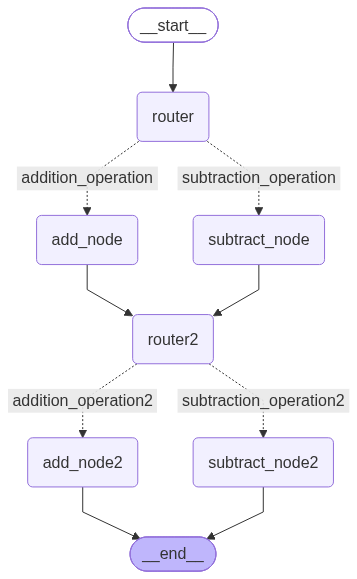

In [47]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [48]:
state: AgentState = {
    "number1": 10,
    "operation": "-",
    "number2": 5,
    "number3": 7,
    "number4": 2,
    "operation2": "+",
    "finalNumber": 0,
    "finalNumber2": 0
}

result = app.invoke(state)
print(f"finalNumber  10 - 5 = {result['finalNumber']}")
print(f"finalNumber2 5 + 7 + 2 = {result['finalNumber2']}")

finalNumber  10 - 5 = 5
finalNumber2 5 + 7 + 2 = 14
